# Function Transformer


In [ ]:
import pandas as pd  
import numpy as np

import scipy.stats as stats    # For Q-Q Plot

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [24]:
df = pd.read_csv('DataSets/train.csv',usecols=['Age', 'Fare', 'Survived'])

In [25]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [26]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [27]:
df['Age'].fillna(df['Age'].mean(),inplace=True)

C:\Users\Snehal\AppData\Local\Temp\ipykernel_16756\694922604.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(),inplace=True)


In [28]:
X = df.iloc[:,1:3]
y = df.iloc[:,0]

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

C:\Users\Snehal\AppData\Local\Temp\ipykernel_16756\642700146.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Age'])


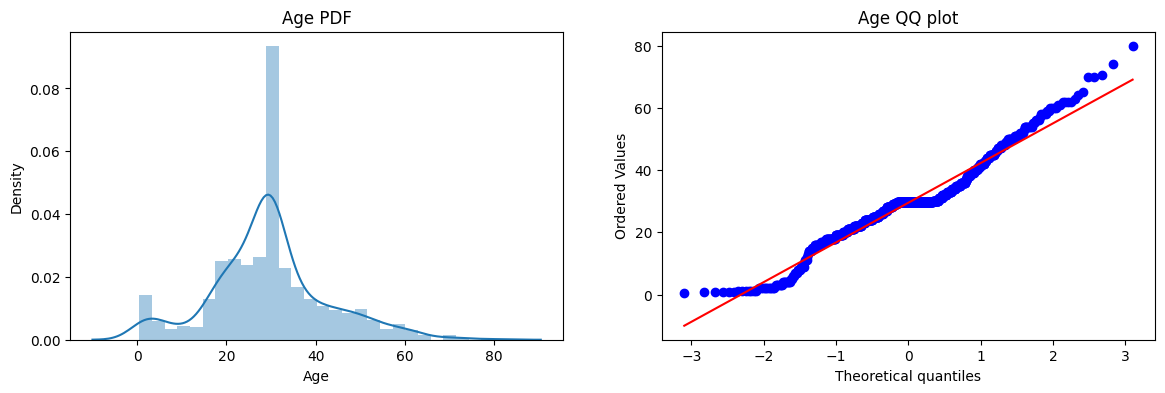

In [30]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(X_train['Age'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(X_train['Age'], dist='norm',plot=plt)
plt.title("Age QQ plot")

plt.show()

C:\Users\Snehal\AppData\Local\Temp\ipykernel_16756\3908125623.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Fare'])


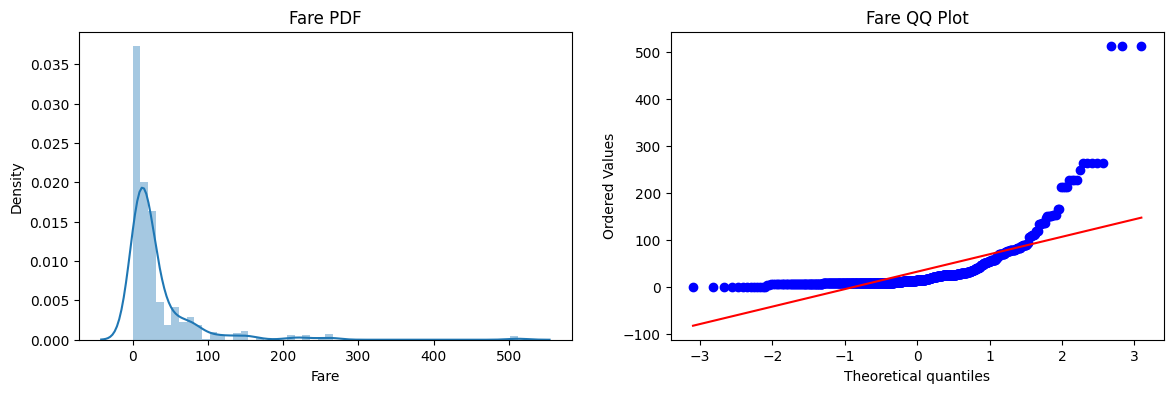

In [32]:

plt.figure(figsize=(14,4))

plt.subplot(121)
sns.distplot(X_train['Fare'])
plt.title('Fare PDF')

plt.subplot(122)
stats.probplot(X_train['Fare'], dist='norm', plot=plt)
plt.title('Fare QQ Plot')

plt.show()

In [44]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [45]:
clf.fit(X_train, y_train)
clf2.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_pred1 = clf2.predict(X_test)

print('Accuracy LR:', accuracy_score(y_test, y_pred))
print('Accuracy DT:', accuracy_score(y_test, y_pred1))

Accuracy LR: 0.6480446927374302
Accuracy DT: 0.6759776536312849


In [46]:
trf = FunctionTransformer(func=np.log1p)

In [47]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

In [48]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed,y_train)

y_pred = clf.predict(X_test)
y_pred1 = clf2.predict(X_test)

print('Accuracy LR:', accuracy_score(y_test, y_pred))
print('Accuracy DT:', accuracy_score(y_test, y_pred1))


Accuracy LR: 0.7374301675977654
Accuracy DT: 0.5865921787709497


In [49]:
X_transformed = trf.fit_transform(X)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print('LR',np.mean(cross_val_score(clf,X_transformed,y,scoring='accuracy', cv=10)))
print('LR',np.mean(cross_val_score(clf2,X_transformed,y,scoring='accuracy', cv=10)))

LR 0.678027465667915
LR 0.6577403245942571


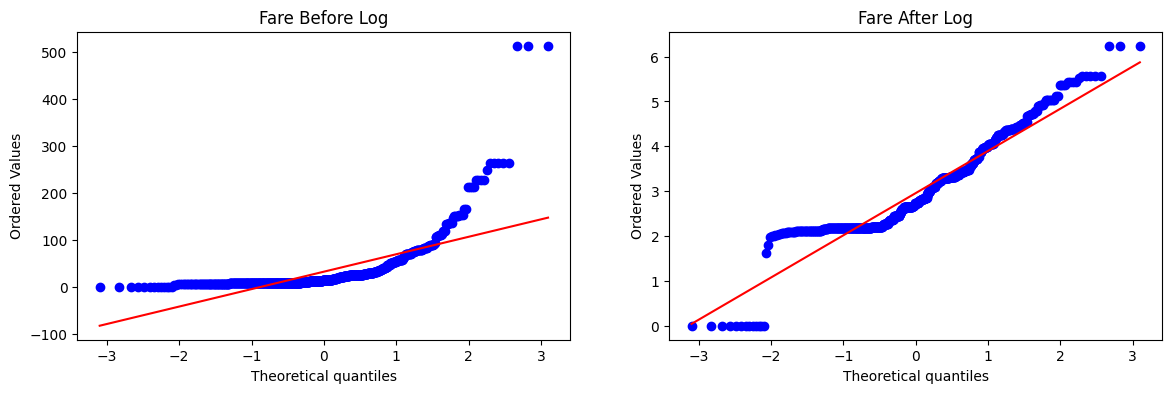

In [52]:
plt.figure(figsize =(14,4))

plt.subplot(121)
stats.probplot(X_train['Fare'], dist='norm', plot=plt)
plt.title('Fare Before Log')

plt.subplot(122)
stats.probplot(X_train_transformed['Fare'], dist='norm', plot=plt)
plt.title('Fare After Log')

plt.show()

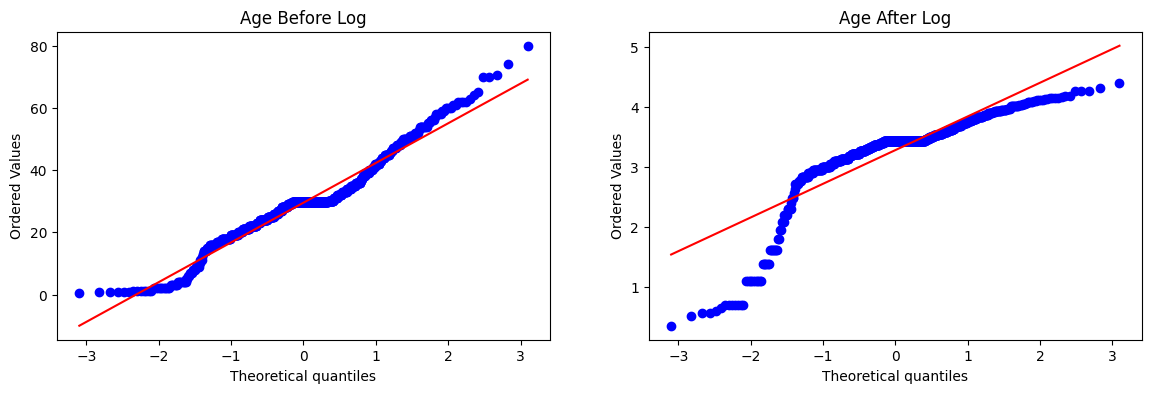

In [53]:
plt.figure(figsize =(14,4))

plt.subplot(121)
stats.probplot(X_train['Age'], dist='norm', plot=plt)
plt.title('Age Before Log')

plt.subplot(122)
stats.probplot(X_train_transformed['Age'], dist='norm', plot=plt)
plt.title('Age After Log')

plt.show()

In [54]:
trf2 = ColumnTransformer([('log', FunctionTransformer(np.log1p),['Fare'])], remainder='passthrough')

X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 = trf2.transform(X_test)

In [56]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed,y_train)

y_pred = clf.predict(X_test_transformed2)
y_pred2 = clf2.predict(X_test_transformed2)

print('Accuracy LR:', accuracy_score(y_test, y_pred))
print('Accuracy DT:', accuracy_score(y_test, y_pred2))


Accuracy LR: 0.40782122905027934
Accuracy DT: 0.3128491620111732


c:\Users\Snehal\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
c:\Users\Snehal\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [57]:
X_transformed2 = trf2.fit_transform(X)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print('LR',np.mean(cross_val_score(clf,X_transformed2,y,scoring='accuracy', cv=10)))
print('DT',np.mean(cross_val_score(clf2,X_transformed2,y,scoring='accuracy', cv=10)))


LR 0.6712609238451936
DT 0.6655430711610487


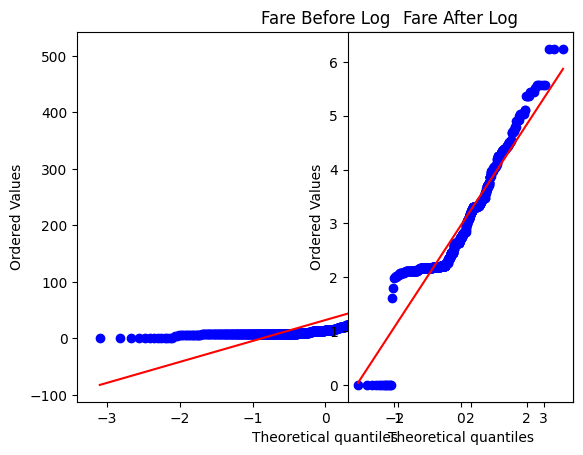

In [64]:
def apply_transform(transform):

    X = df.iloc[:,1:3]
    y = df.iloc[:,0]

    trf = ColumnTransformer([('log', FunctionTransformer(transform), ['Fare'])],
        remainder='passthrough')

    X_trans = trf.fit_transform(X)

    clf = LogisticRegression()

    print("Accuracy",np.mean(cross_val_score(clf,X_trans,y,scoring='accuracy',cv=10)))

    plt.figure(figsize=(14,4))

    plt.subplot(121)
stats.probplot(X_train['Fare'], dist='norm', plot=plt)
plt.title('Fare Before Log')

plt.subplot(122)
stats.probplot(X_train_transformed['Fare'], dist='norm', plot=plt)
plt.title('Fare After Log')

plt.show()

Accuracy 0.6431335830212235


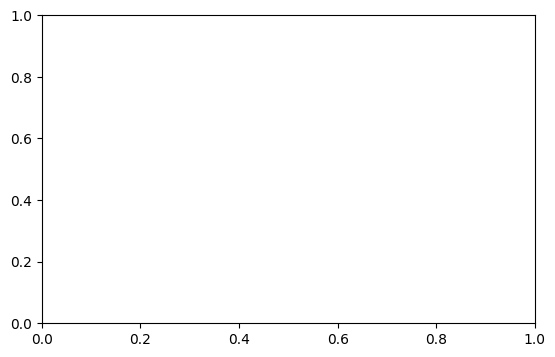

In [65]:
apply_transform(lambda x:  x**2)

# Box-Cox and Yeo Johnson Transform

In [15]:
import pandas as pd  
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import scipy.stats as stats    # For Q-Q Plot

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import PowerTransformer

In [3]:
df = pd.read_csv('E:\BRAINWORk\Machine Learning\placement-project\DataSets\concrete_data.csv')
df.head()

<>:1: SyntaxWarning: invalid escape sequence '\B'
<>:1: SyntaxWarning: invalid escape sequence '\B'
C:\Users\Snehal\AppData\Local\Temp\ipykernel_25456\3169118243.py:1: SyntaxWarning: invalid escape sequence '\B'
  df = pd.read_csv('E:\BRAINWORk\Machine Learning\placement-project\DataSets\concrete_data.csv')


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [5]:
df.shape

(1030, 9)

In [6]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [7]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [8]:
X = df.drop(columns=['Strength'])
y = df.iloc[:, -1]

In [9]:
X_train,X_test,y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [10]:
# Applying regession without any transformation

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
r2_score(y_test, y_pred)

0.6275531792314848

In [11]:
# cross checking with cross val score
lr = LinearRegression()
np.mean(cross_val_score(lr,X,y,scoring='r2'))


np.float64(0.4609940491662864)

C:\Users\Snehal\AppData\Local\Temp\ipykernel_25456\3877016800.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


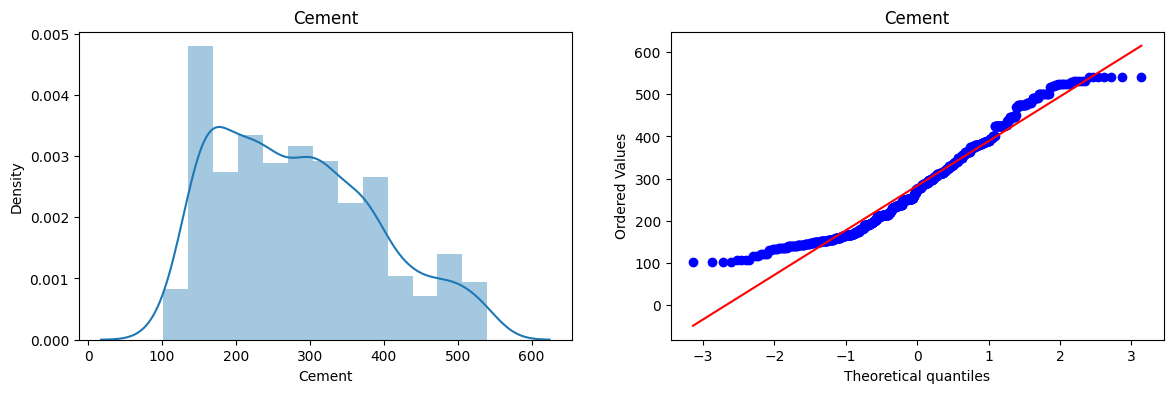

C:\Users\Snehal\AppData\Local\Temp\ipykernel_25456\3877016800.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


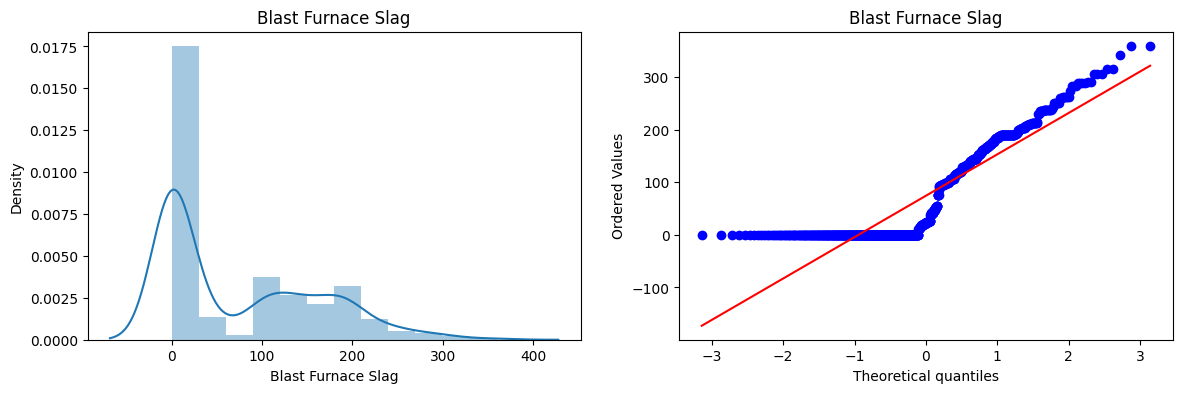

C:\Users\Snehal\AppData\Local\Temp\ipykernel_25456\3877016800.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


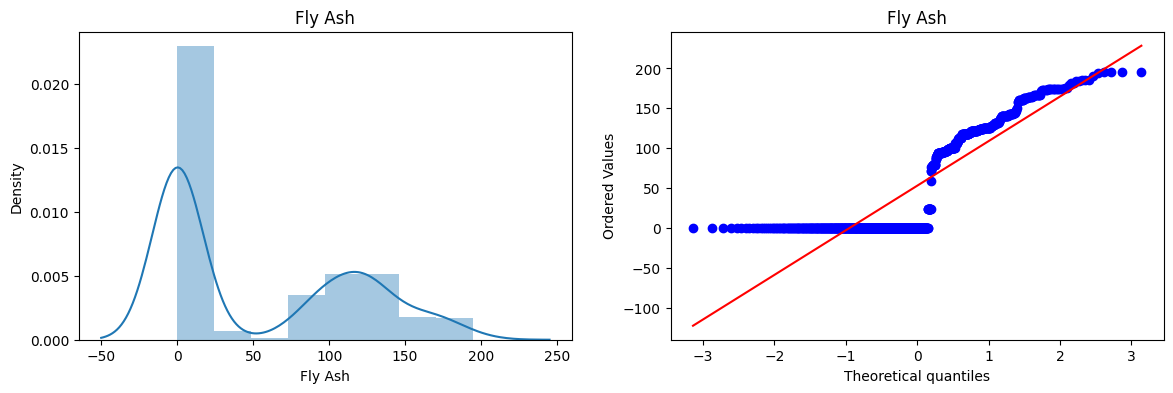

C:\Users\Snehal\AppData\Local\Temp\ipykernel_25456\3877016800.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


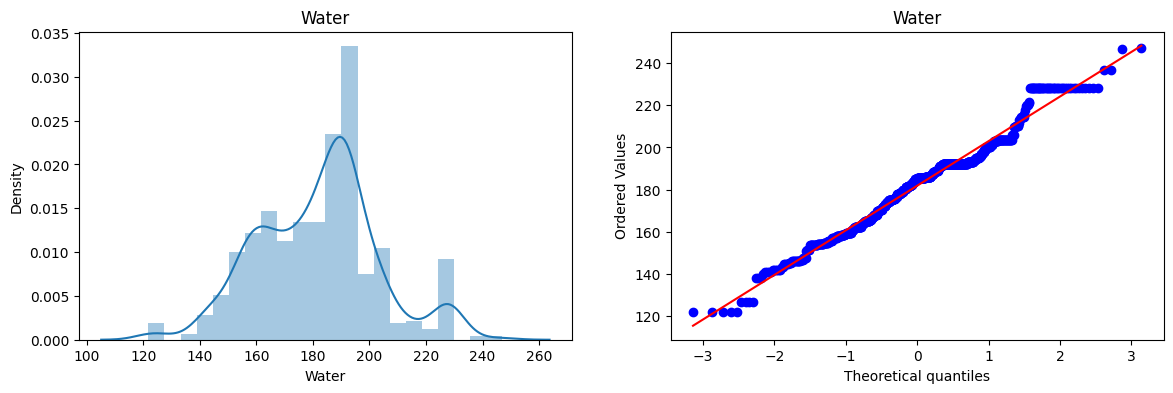

C:\Users\Snehal\AppData\Local\Temp\ipykernel_25456\3877016800.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


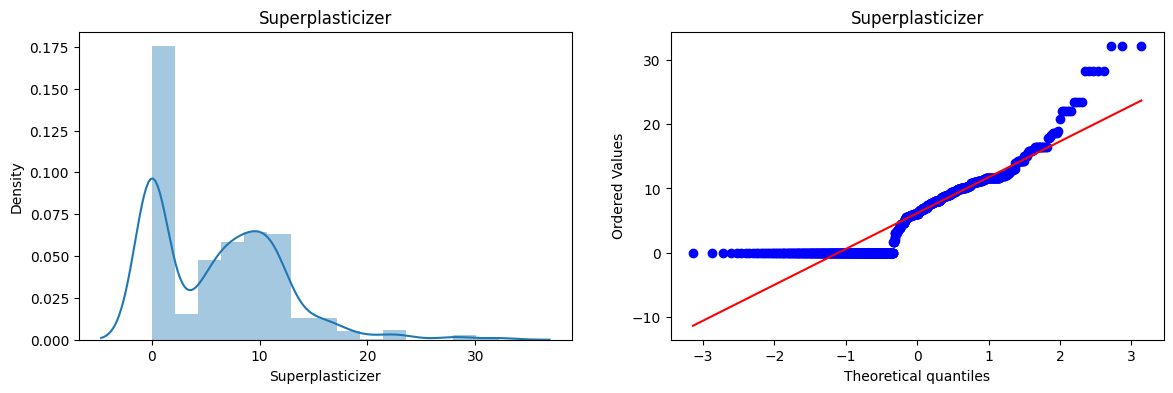

C:\Users\Snehal\AppData\Local\Temp\ipykernel_25456\3877016800.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


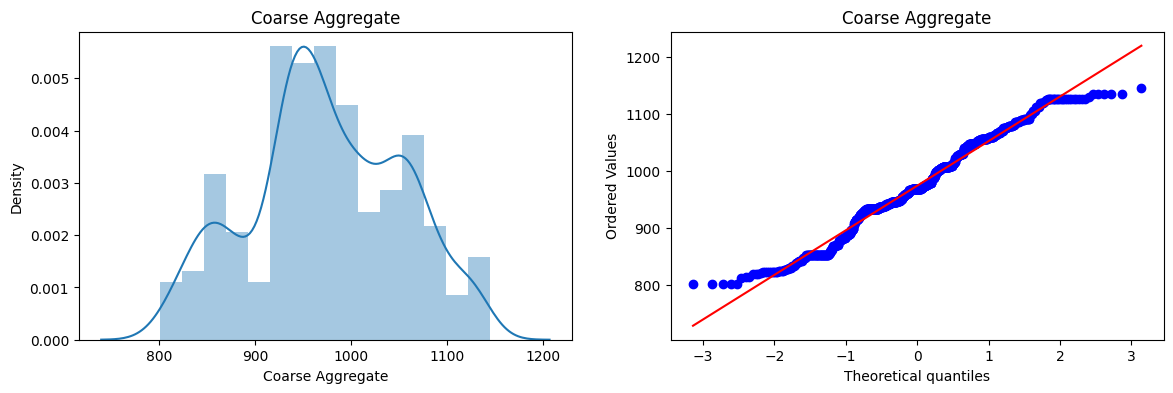

C:\Users\Snehal\AppData\Local\Temp\ipykernel_25456\3877016800.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


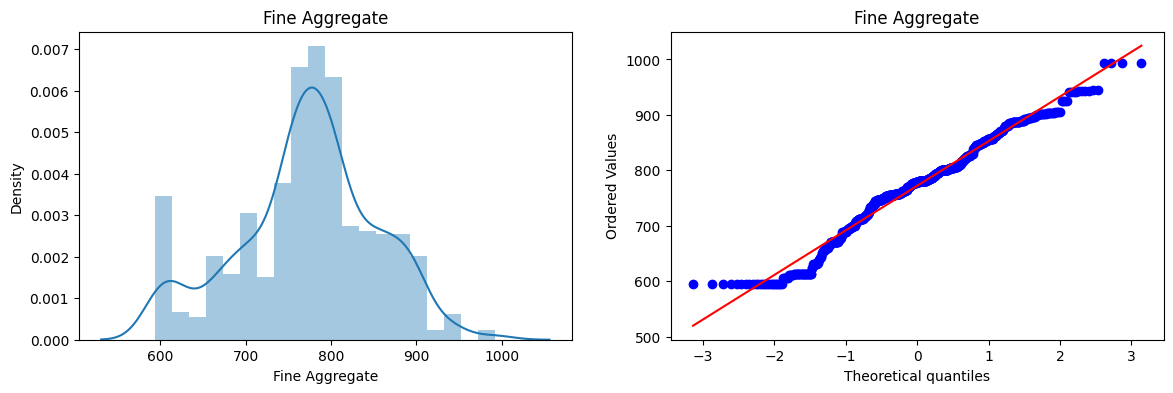

C:\Users\Snehal\AppData\Local\Temp\ipykernel_25456\3877016800.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[col])


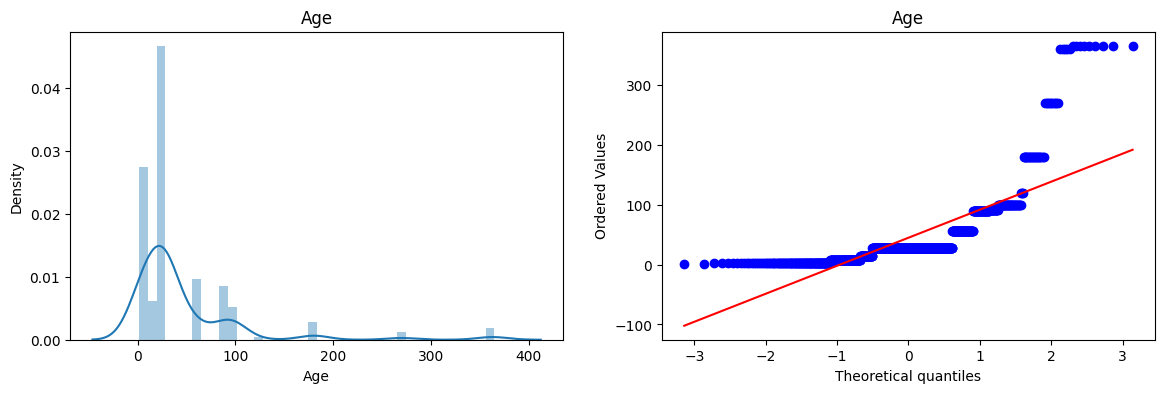

In [13]:
# plotting the distplots without any transformation

for col in X_train.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.distplot(X_train[col])
    plt.title(col)

    plt.subplot(122)
    stats.probplot(X_train[col], dist='norm', plot=plt)
    plt.title(col)

    plt.show()

In [31]:
# applying Box-Cox transform

from sklearn.preprocessing import PowerTransformer

# 1. Initialize the transformer (Note the corrected spelling: PowerTransformer)
pt = PowerTransformer(method='box-cox')

# 2. Fit and transform the training data, adding a small constant to ensure strictly positive values
X_train_transformed = pt.fit_transform(X_train + 0.00001)
X_test_transformed = pt.transform(X_test + 0.00001)

# 4. Extract and view the optimal lambda values found for each column
lambdas_df = pd.DataFrame({'cols': X_train.columns,'box_cox_lambdas': pt.lambdas_})
print(lambdas_df)

                 cols  box_cox_lambdas
0              Cement         0.177025
1  Blast Furnace Slag         0.027842
2             Fly Ash        -0.044554
3               Water         0.772682
4    Superplasticizer         0.113892
5    Coarse Aggregate         1.129813
6      Fine Aggregate         1.782018
7                 Age         0.066630


In [32]:
# Applying linear regression on transformed data

lr = LinearRegression()
lr.fit(X_train_transformed,y_train)

y_pred2 = lr.predict(X_test_transformed)
r2_score(y_test, y_pred2)

0.8054599366002649

In [33]:
# Using cross val score

pt = PowerTransformer(method='box-cox')
X_transformed = pt.fit_transform(X + 0.0000001)

lr = LinearRegression()
np.mean(cross_val_score(lr,X_transformed,y,scoring='r2'))

np.float64(0.6658537941434357)

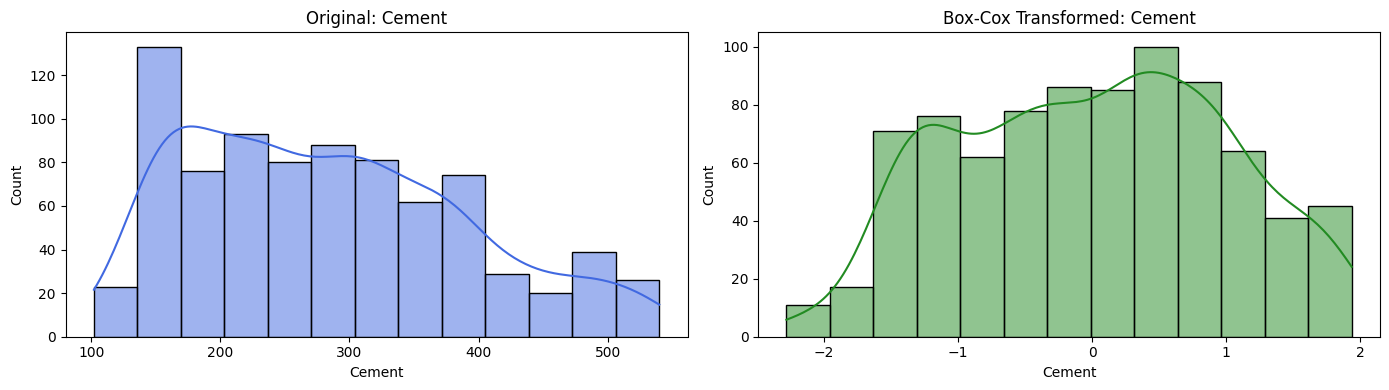

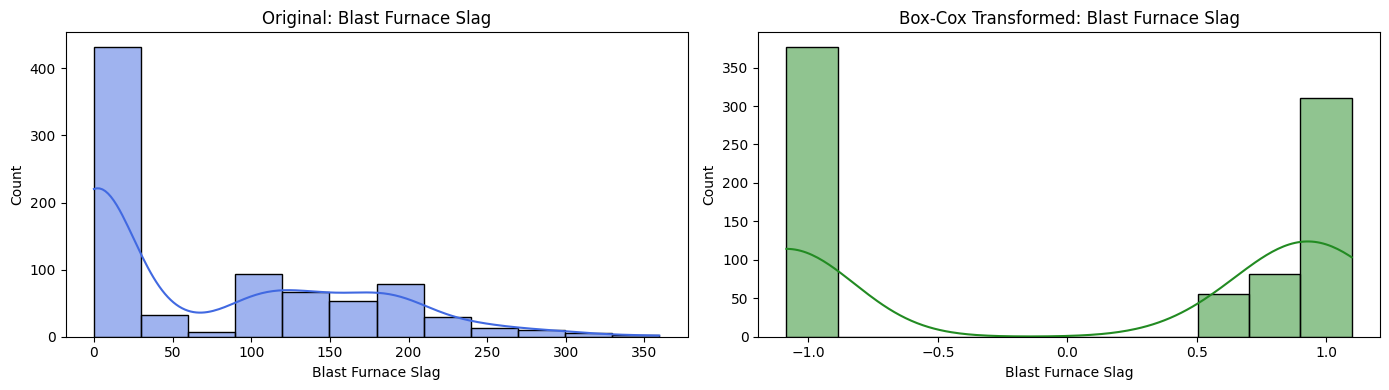

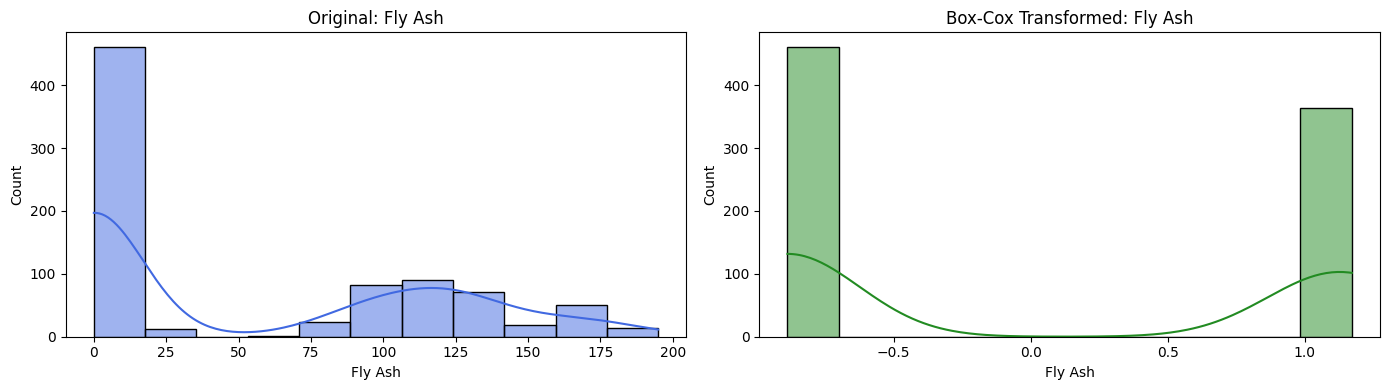

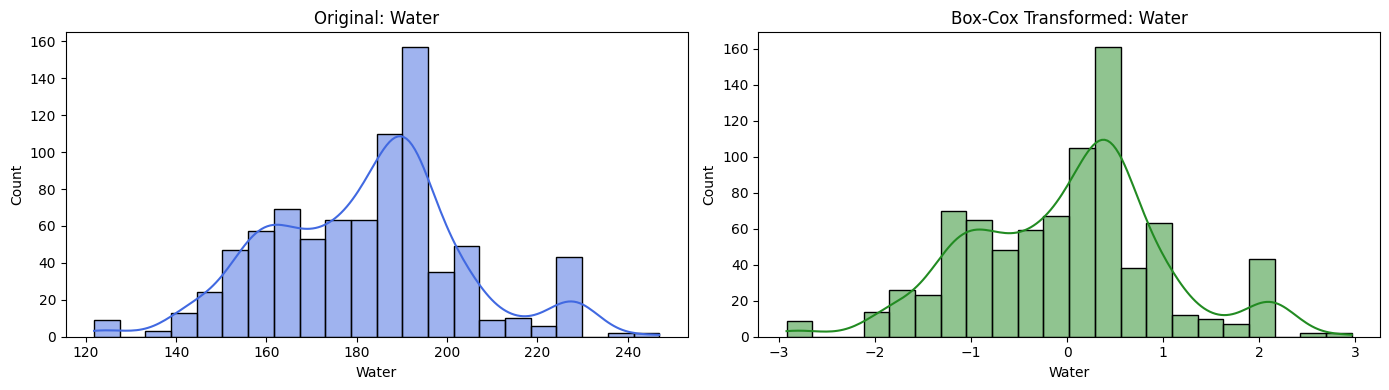

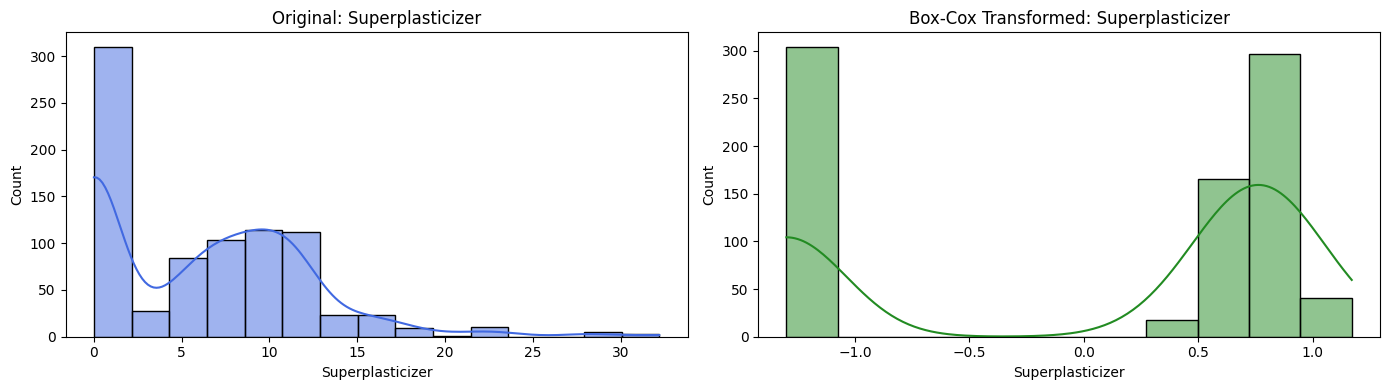

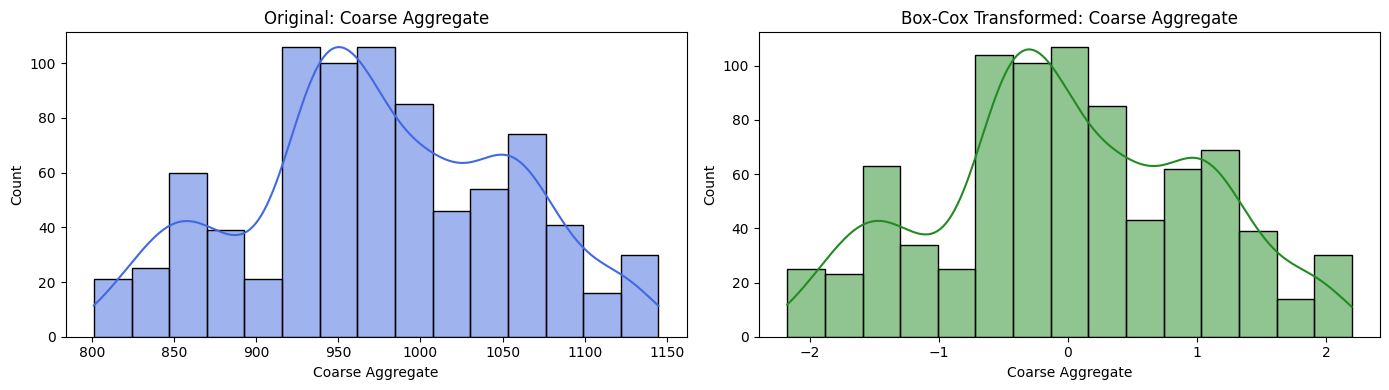

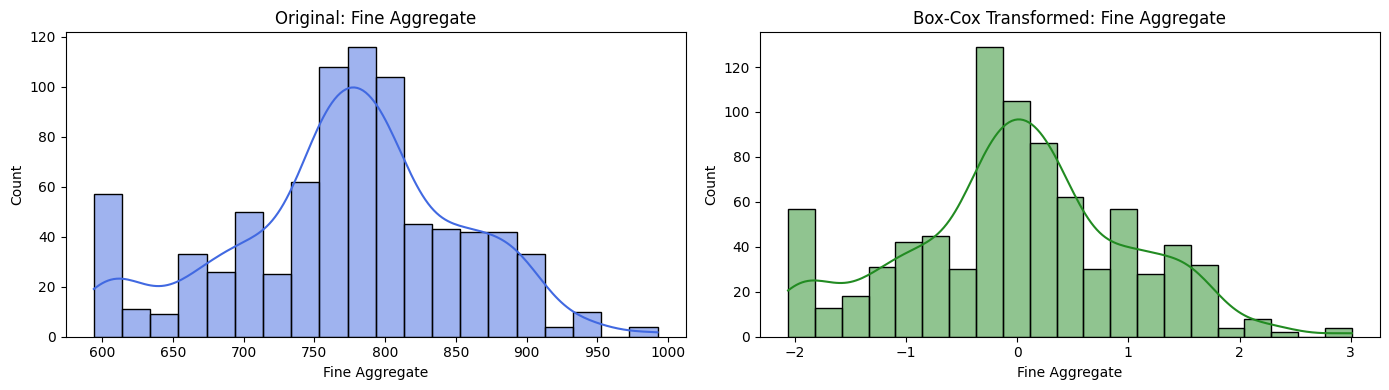

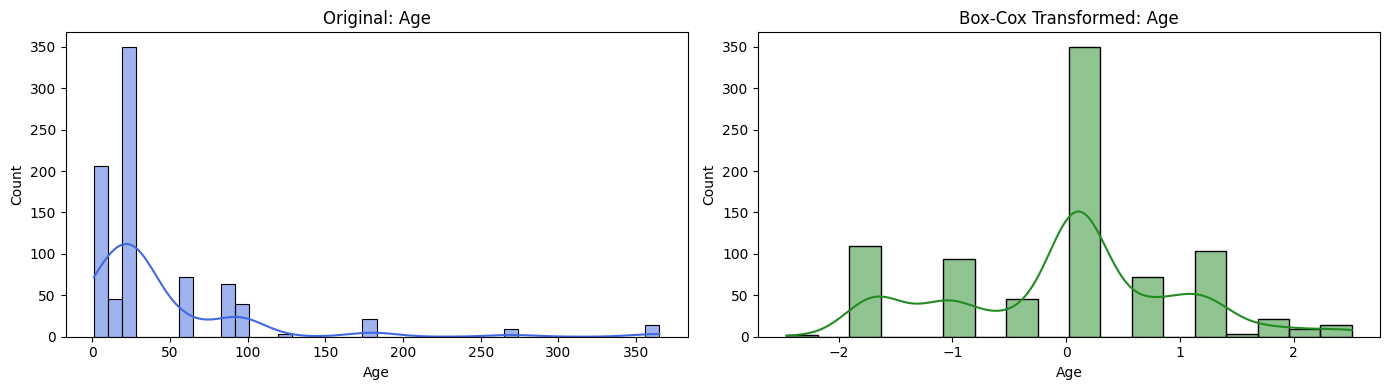

In [36]:
# Before and after comparison for box cox plot

# 1. Convert to DataFrame using a clean, distinct variable name
X_train_transformed_df = pd.DataFrame(X_train_transformed, columns=X_train.columns)

# 2. Plotting loop
for col in X_train_transformed_df.columns:
    plt.figure(figsize=(14, 4))
    
    # Left Plot: Before Transformation
    plt.subplot(121)
    sns.histplot(X_train[col], kde=True, color='royalblue')
    plt.title(f"Original: {col}")
    
    # Right Plot: After Box-Cox Transformation
    plt.subplot(122)
    sns.histplot(X_train_transformed_df[col], kde=True, color='forestgreen')
    plt.title(f"Box-Cox Transformed: {col}")
    
    plt.tight_layout()
    plt.show()

In [37]:
# Apply yeo_johnson transform

pt1 = PowerTransformer()

X_train_transformed2 = pt1.fit_transform(X_train)
X_test_transformed2 = pt1.transform(X_test)

lr = LinearRegression()
lr.fit(X_train_transformed2,y_train)

y_pred3 = lr.predict(X_test_transformed2)
print(r2_score(y_test, y_pred3))

pd.DataFrame({'cols': X_train.columns,'yeo_johnson_lambdas': pt1.lambdas_})


0.8161906511066098


,cols,yeo_johnson_lambdas
0,Cement,0.174348
1,Blast Furnace Slag,0.015715
2,Fly Ash,-0.161447
3,Water,0.771307
4,Superplasticizer,0.253935
5,Coarse Aggregate,1.130050
6,Fine Aggregate,1.783100
7,Age,0.019885


In [41]:
# Applying croass val score

pt = PowerTransformer()
X_transformed2 = pt.fit_transform(X)

lr = LinearRegression()
np.mean(cross_val_score(lr,X_transformed2,y,scoring='r2'))

np.float64(0.6834625126992443)

In [42]:

X_train_transformed_df = pd.DataFrame(X_train_transformed, columns=X_train.columns)

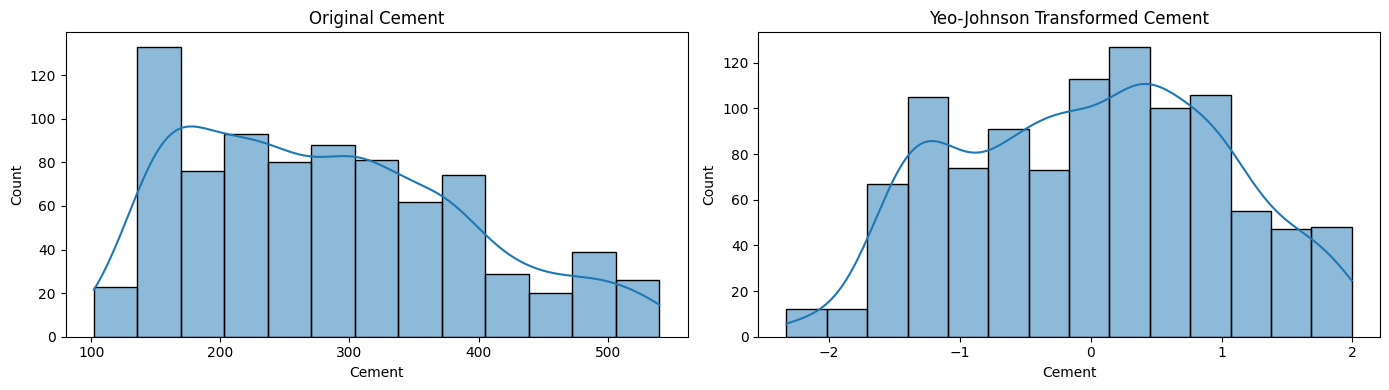

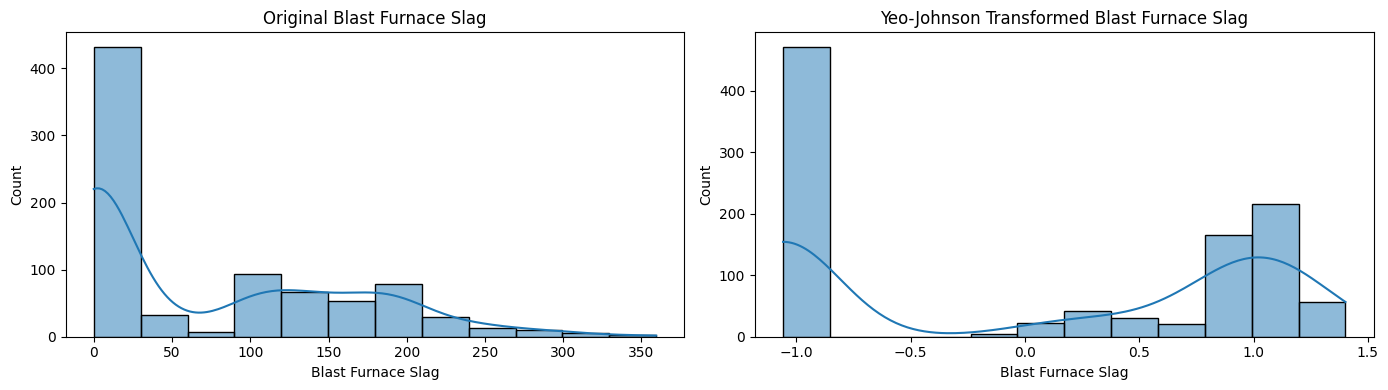

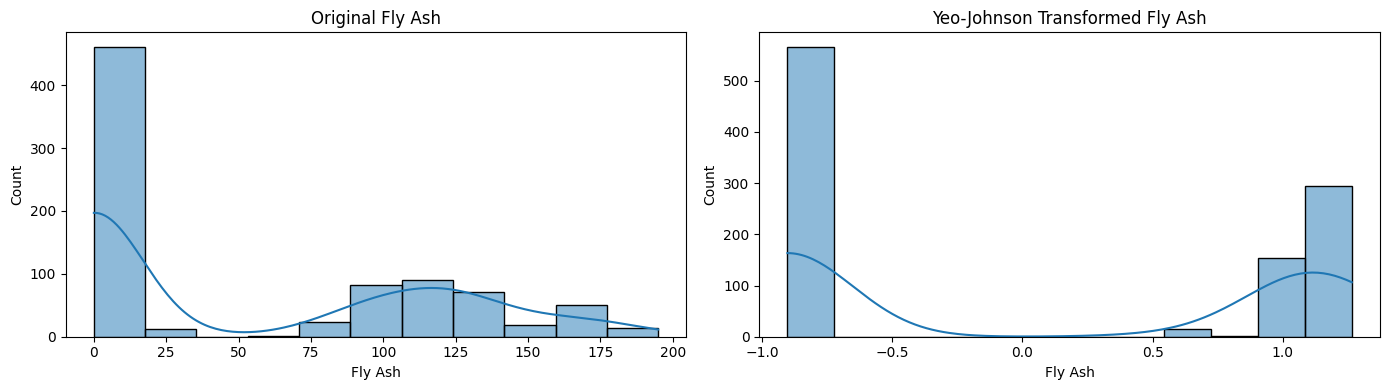

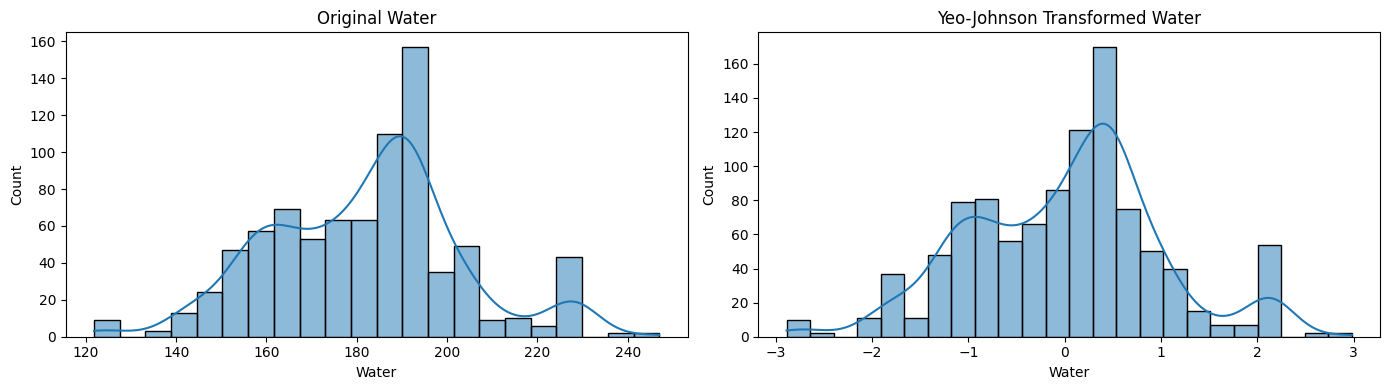

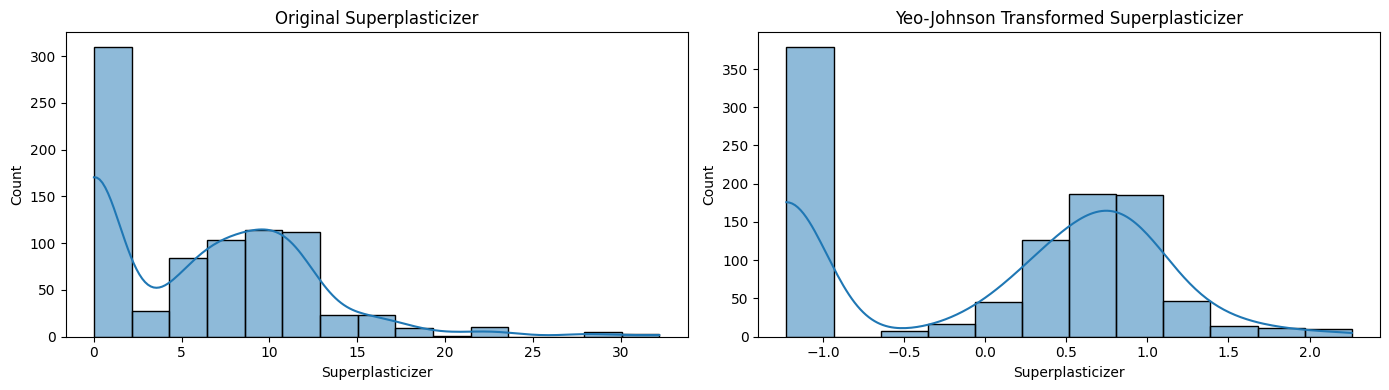

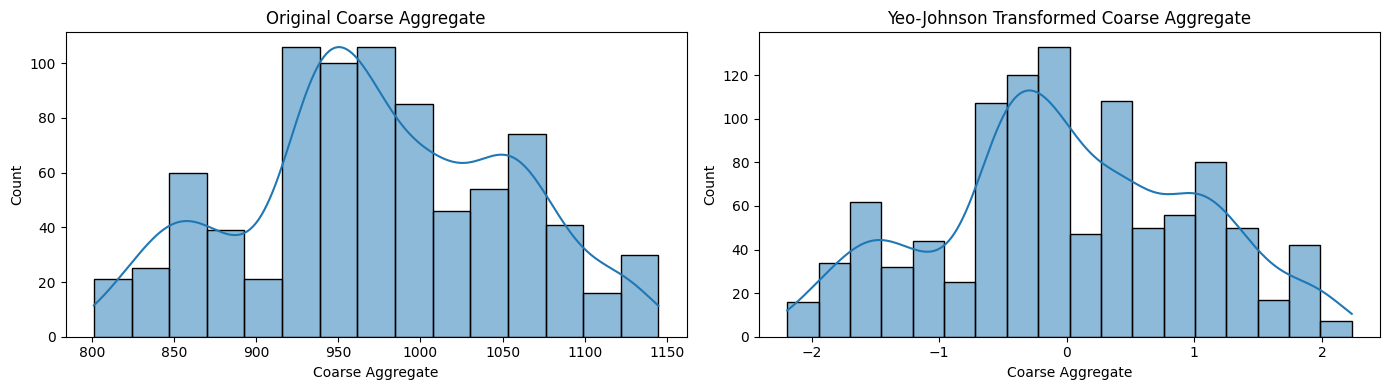

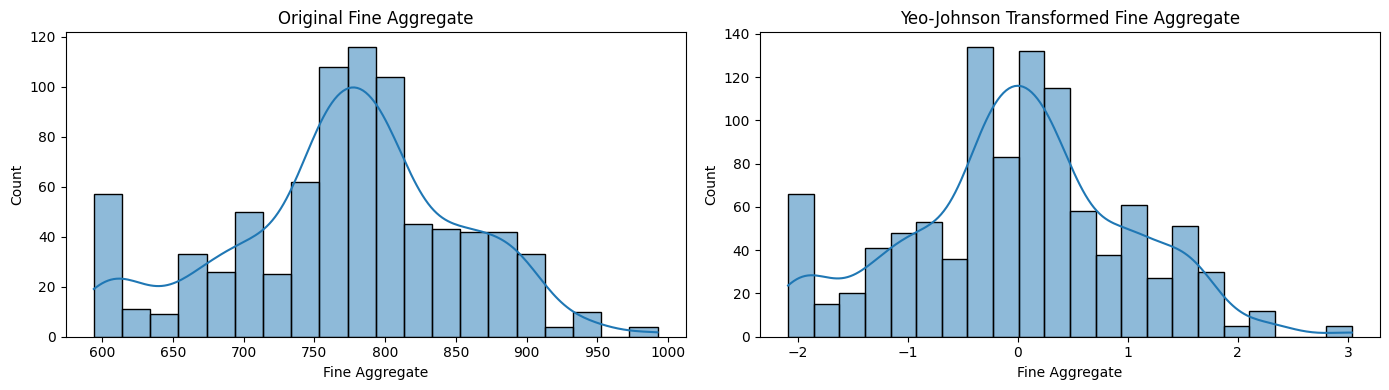

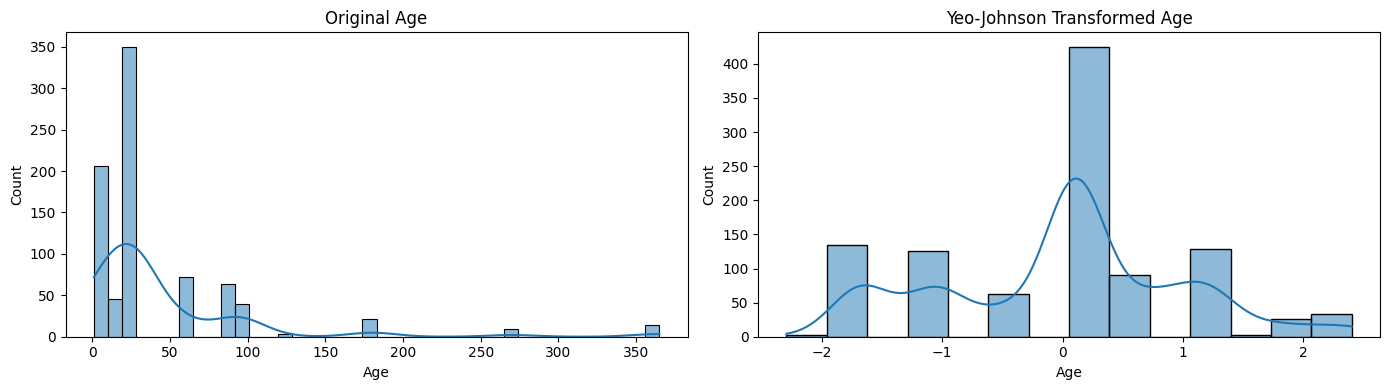

In [45]:
# Before and after comparison for yeo-johnson 

# FIX: Convert the Yeo-Johnson array (transformed2) into a DataFrame
X_train_transformed2_df = pd.DataFrame(X_train_transformed2, columns=X_train.columns)

# Loop through the newly created DataFrame's columns
for col in X_train_transformed2_df.columns:
    plt.figure(figsize=(14,4))
    
    # Left plot: Original data
    plt.subplot(121)
    sns.histplot(X_train[col], kde=True)  # Updated to modern histplot
    plt.title(f"Original {col}")

    # Right plot: Yeo-Johnson transformed data
    plt.subplot(122)
    sns.histplot(X_train_transformed2_df[col], kde=True)  # Updated to modern histplot
    plt.title(f"Yeo-Johnson Transformed {col}")

    plt.tight_layout()
    plt.show()

In [46]:
# side by side lambdas

pd.DataFrame({'cols':X_train.columns,'box_cox_lambdas':pt.lambdas_,'yeo_johnson_lambdas':pt1.lambdas_})

,cols,box_cox_lambdas,yeo_johnson_lambdas
0,Cement,0.169544,0.174348
1,Blast Furnace Slag,0.016633,0.015715
2,Fly Ash,-0.136480,-0.161447
3,Water,0.808438,0.771307
4,Superplasticizer,0.264160,0.253935
5,Coarse Aggregate,1.129395,1.130050
6,Fine Aggregate,1.830764,1.783100
7,Age,0.001771,0.019885
